# À qui la Guinée vend-elle ses minerais ? La dépendance à la Chine (2015-2025)

**Question :** quels pays achètent la bauxite et l'or de la Guinée, quelle place occupe la Chine, et qu'est-ce que cela implique pour le pays ?

**Source : données « miroir » UN Comtrade.** La Guinée ne déclare plus son commerce extérieur à la base de l'ONU. On utilise donc l'autre côté de la transaction : ce que chaque pays déclare avoir importé **depuis** la Guinée. Les valeurs sont « CIF » : elles incluent le transport et l'assurance jusqu'au pays acheteur.

Script de téléchargement : `src/telecharger_comtrade.py` (API publique UN Comtrade, 2015-2025, codes SH 2606 bauxite, 7108 or, 2601 minerai de fer, 2818 alumine). Fichier : `data/comtrade_miroir.csv`. Requêtes : `sql/03_*.sql`.

In [1]:
import sys
sys.path.append("..")

from src.requetes import requete
from src.graphiques import graphique_chine_bauxite, graphique_prix_tonne, graphique_or_clients

## 0. Contrôle qualité : peut-on se fier aux tonnages déclarés par les acheteurs ?

In [2]:
requete("03_controle_tonnages").show()

┌───────┬──────────────┬───────────┬────────────────┬───────────────┐
│ annee │ ministere_mt │ miroir_mt │ couverture_pct │ poids_estimes │
│ int64 │    double    │  double   │     double     │     int64     │
├───────┼──────────────┼───────────┼────────────────┼───────────────┤
│  2019 │         66.3 │      63.6 │           96.0 │             1 │
│  2020 │         82.6 │      76.4 │           93.0 │             1 │
│  2021 │         85.7 │      77.7 │           91.0 │             0 │
│  2022 │        102.3 │      88.8 │           87.0 │             1 │
│  2023 │        126.6 │      34.3 │           27.0 │             4 │
│  2024 │        145.9 │     122.5 │           84.0 │             1 │
│  2025 │        182.8 │     162.8 │           89.0 │             0 │
└───────┴──────────────┴───────────┴────────────────┴───────────────┘



**Constat :** sur la plupart des années, les acheteurs déclarent 84 à 96 % des tonnes que le Ministère des Mines dit avoir exportées. L'écart restant s'explique par les décalages de date (un navire parti en décembre arrive en janvier) et par les pays qui ne déclarent pas. Mais en **2023**, les tonnages miroirs ne couvrent que 27 % du total : le poids déclaré par la Chine a été **estimé** par l'ONU (13,8 Mt au lieu d'environ 100). Conclusion : dans la suite, je travaille sur les **valeurs en dollars**, plus fiables que les poids, et j'écarte les poids estimés.

## 1. Ce que le monde achète à la Guinée

In [3]:
requete("03_poids_par_produit").df().round(2)

,annee,bauxite,orr,alumine,fer
0,2015,0.83,0.56,NaN,0.00
1,2016,1.17,1.54,NaN,0.00
2,2017,2.03,3.27,NaN,NaN
3,2018,2.86,2.79,0.08,0.00
4,2019,3.33,2.85,0.14,0.00
5,2020,3.45,8.19,0.13,0.02
6,2021,3.76,5.79,0.15,0.09
7,2022,5.47,5.41,0.03,0.02
8,2023,7.62,9.65,0.04,0.00
9,2024,8.32,0.45,0.00,0.02


**Constat :** la bauxite et l'or représentent presque tout ; l'alumine et le minerai de fer sont marginaux (Simandou n'exporte qu'à partir de fin 2025). Attention à l'or en 2024-2025 : la chute de 9,7 à 0,5 milliard de dollars n'est pas réelle, elle vient de déclarations manquantes (partie 5).

## 2. La Chine, acheteur quasi unique de la bauxite

,annee,pays_acheteurs,total_milliards_usd,chine_milliards_usd,part_chine_pct
0,2015,9,0.83,0.02,2.41
1,2016,10,1.17,0.62,53.35
2,2017,13,2.03,1.45,71.69
3,2018,13,2.86,2.19,76.43
4,2019,14,3.33,2.46,73.65
5,2020,18,3.45,2.42,69.98
6,2021,12,3.76,2.70,71.90
7,2022,12,5.47,4.50,82.27
8,2023,11,7.62,6.39,83.86
9,2024,8,8.32,7.59,91.26


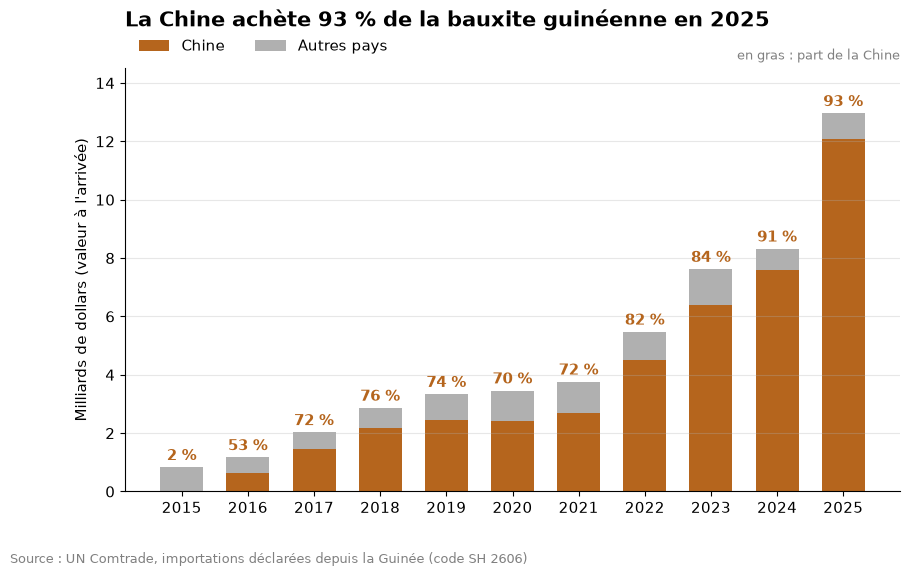

In [4]:
chine = requete("03_bauxite_chine_par_annee").df()
display(chine.round(2))
graphique_chine_bauxite(chine)

**Conclusion :** en 2015, la Chine n'achetait presque pas de bauxite guinéenne (2 %). Un an plus tard, elle en achète la moitié, puis plus de 70 % dès 2017, et **93 % en 2025**, pour 12,1 milliards de dollars. Ce basculement suit l'interdiction d'exporter de la bauxite brute décidée par l'Indonésie en 2014, alors premier fournisseur de la Chine. Dans le même temps, le nombre de pays acheteurs diminue (14 en 2019, 8 à 10 en 2024-2025).

## 3. Une clientèle qui a complètement changé en dix ans

In [5]:
requete("03_clients_bauxite", debut=2015, fin=2025).show()

┌───────┬──────────────────┬──────────────┬──────────┐
│ annee │ pays_importateur │ millions_usd │ part_pct │
│ int64 │     varchar      │    double    │  double  │
├───────┼──────────────────┼──────────────┼──────────┤
│  2015 │ Spain            │        168.0 │     20.3 │
│  2015 │ Ireland          │        162.0 │     19.6 │
│  2015 │ Ukraine          │        114.0 │     13.7 │
│  2015 │ Germany          │        111.0 │     13.3 │
│  2015 │ USA              │        102.0 │     12.3 │
│  2015 │ France           │         55.0 │      6.6 │
│  2025 │ China            │      12064.0 │     93.1 │
│  2025 │ India            │        377.0 │      2.9 │
│  2025 │ Ireland          │        199.0 │      1.5 │
│  2025 │ Germany          │        147.0 │      1.1 │
│  2025 │ Spain            │        107.0 │      0.8 │
│  2025 │ Canada           │         48.0 │      0.4 │
└───────┴──────────────────┴──────────────┴──────────┘
  12 rows                                  4 columns



**Conclusion :** en 2015, la bauxite guinéenne allait vers l'Europe et l'Amérique du Nord (Espagne, Irlande, Ukraine, Allemagne, États-Unis), vers des raffineries d'alumine. En 2025, ces clients historiques achètent toujours à peu près les mêmes volumes, mais ils ne pèsent plus que quelques pourcents face à la Chine. La croissance de la bauxite guinéenne est **entièrement chinoise**.

## 4. Combien vaut une tonne de bauxite à son arrivée en Chine ?

,annee,usd_par_tonne,millions_tonnes
0,2015,60.6,0.3
1,2017,52.7,27.6
2,2018,57.3,38.2
3,2019,55.3,44.4
4,2020,45.8,52.7
5,2021,49.4,54.7
6,2022,64.0,70.4
7,2024,68.9,110.1
8,2025,80.7,149.5


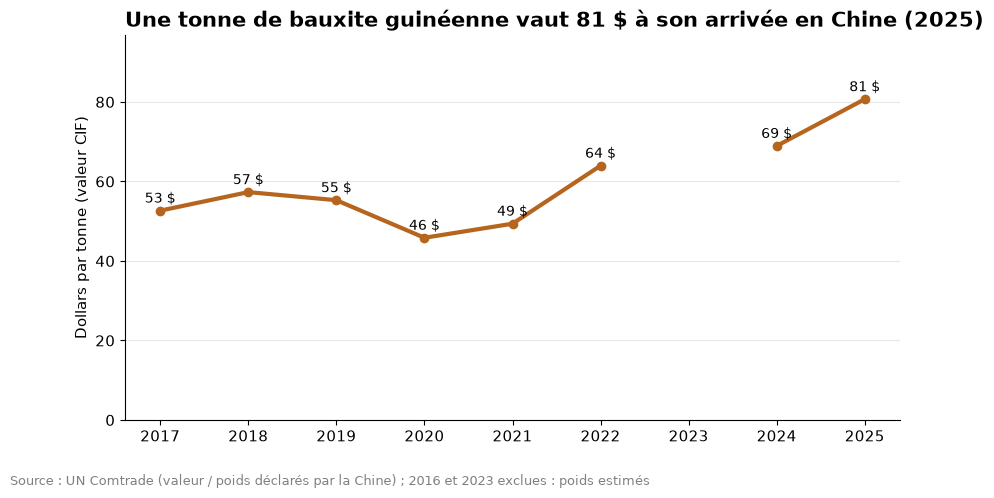

In [6]:
prix = requete("03_prix_tonne_chine").df()
display(prix.round(1))
graphique_prix_tonne(prix)

**Conclusion :** la tonne de bauxite guinéenne vaut entre 46 $ (2020) et 81 $ (2025) à son arrivée en Chine. À mettre en regard de l'étape 2 :
- l'État touche environ **3 $ de taxe minière par tonne** exportée ;
- l'INS évalue les exportations de bauxite de 2024 à 4,7 milliards de dollars (environ 32 $ la tonne au départ de Guinée), alors que les acheteurs déclarent **8,3 milliards** (69 $ la tonne pour la Chine).

Le transport maritime jusqu'en Chine et l'assurance expliquent une partie de l'écart, mais probablement pas la totalité. C'est une piste à creuser : une valeur à l'export sous-estimée réduit les taxes calculées sur cette valeur.

## 5. L'or : les Émirats, et un trou dans les données

In [7]:
requete("03_or_par_client").df().round(0)

,annee,pays_acheteurs,emirats,inde,suisse,autres,total
0,2015,11,185.0,225.0,29.0,121.0,559.0
1,2016,13,1074.0,113.0,181.0,172.0,1540.0
2,2017,13,2714.0,393.0,28.0,133.0,3267.0
3,2018,14,2272.0,291.0,28.0,199.0,2789.0
4,2019,14,2234.0,224.0,127.0,267.0,2853.0
5,2020,10,6618.0,813.0,277.0,482.0,8190.0
6,2021,11,2336.0,3156.0,240.0,61.0,5794.0
7,2022,9,2453.0,2414.0,345.0,199.0,5410.0
8,2023,10,8364.0,1038.0,240.0,12.0,9653.0
9,2024,10,0.0,326.0,17.0,108.0,451.0


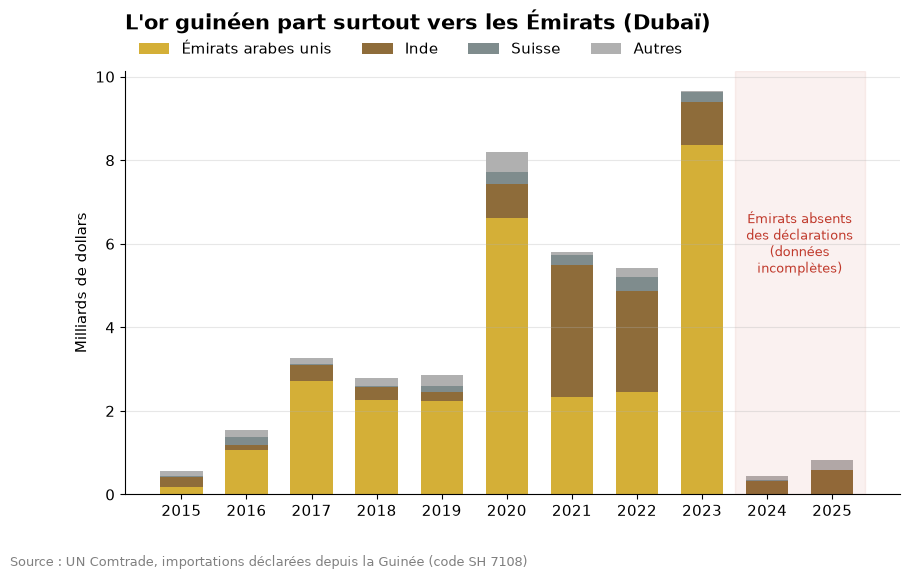

In [8]:
graphique_or_clients(requete("03_or_par_client").df())

**Conclusion :** de 2016 à 2023, les Émirats arabes unis (Dubaï) achètent la majorité de l'or guinéen : 87 % en 2023, pour 8,4 milliards de dollars. L'Inde est le deuxième acheteur, et le premier en 2021. La Chine, elle, n'achète pas d'or guinéen.

**Limite :** les Émirats n'ont pas encore publié leurs importations de 2024 et 2025 dans UN Comtrade. Le total de ces deux années est donc très incomplet et ne doit pas être lu comme une chute des exportations d'or.

## Ce qu'il faut retenir

1. **La Chine achète 93 % de la bauxite guinéenne (2025),** contre 2 % en 2015. La Guinée est passée en dix ans d'une clientèle diversifiée à un acheteur quasi unique.
2. **Une forte dépendance :** un ralentissement de l'industrie de l'aluminium chinoise toucherait directement la première source de devises du pays. Diversifier les clients, ou transformer la bauxite sur place (alumine), sont les deux leviers.
3. **L'or part vers Dubaï :** les Émirats achètent la majorité de l'or guinéen (87 % en 2023).
4. **Un écart de valeur à surveiller :** les acheteurs déclarent environ deux fois plus de valeur que l'INS pour la bauxite de 2024 ; le transport n'explique pas tout.
5. **Qualité des données :** les poids miroirs sont parfois estimés (Chine 2023) et les Émirats n'ont pas déclaré 2024-2025. J'ai travaillé sur les valeurs et signalé chaque trou.

**Prochaine étape :** Simandou et le minerai de fer, et ce que son démarrage peut changer pour l'économie guinéenne.